# Montecarlo del Reto 9: call asiática sobre una cesta de 3 acciones

Valoración con los datos y criterios de la **Descripción técnica** del reto. La estructura del código sigue la receta de clase (sin bucles):

variables aleatorias `X` → correlacionarlas con Cholesky → factores de crecimiento `e` → matriz de trayectorias con `S0` en la primera columna → `np.cumprod(S, axis=1)` → payoff → media → descuento.

Cartera elegida: **WMT + MRK + NVDA** (ver `seleccioncartera.ipynb`).

## 1. Parámetros del enunciado

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

acciones = ["WMT", "MRK", "NVDA"]   # K = 3 activos
S0 = np.array([1.0, 1.0, 1.0])      # precios iniciales normalizados
mu = 0.01                           # tasa libre de riesgo (la misma para los 3)
E = 3.0                             # precio de ejercicio de la cesta
T = 5                               # años hasta el vencimiento
n_times = 20                        # instantes temporales de cada trayectoria (n_pasos)
n_trayectorias = 100_000            # simulaciones

dt = T / n_times                    # 0,25 años

## 2. Volatilidad anual y correlación

Se estiman con las **log-rentabilidades diarias** de los precios ajustados (`adj_close`) de las tres acciones:
- volatilidad anual = desviación típica diaria × √252
- correlación = matriz de correlaciones de las rentabilidades

In [20]:
datos = pd.read_csv("Datos/dowjones_limpio.csv", usecols=["date", "symbol", "adj_close"])
precios_hist = datos.pivot(index="date", columns="symbol", values="adj_close")[acciones]

rent = np.log(precios_hist).diff().dropna()      # log-rentabilidades diarias
sigma = rent.std().to_numpy() * np.sqrt(252)     # volatilidad anual de cada acción
rho = rent.corr().to_numpy()                     # matriz de correlaciones

print("Periodo:", precios_hist.index.min(), "a", precios_hist.index.max())
print("Volatilidad anual:", dict(zip(acciones, sigma.round(3).tolist())))
pd.DataFrame(rho, index=acciones, columns=acciones).round(3)

Periodo: 2018-06-06 00:00:00+00:00 a 2025-12-31 00:00:00+00:00
Volatilidad anual: {'WMT': 0.219, 'MRK': 0.236, 'NVDA': 0.517}


,WMT,MRK,NVDA
WMT,1.000,0.234,0.225
MRK,0.234,1.000,0.129
NVDA,0.225,0.129,1.000


## 3. Cholesky

Para que las tres acciones se muevan juntas hay que correlacionar las variables aleatorias. `np.linalg.cholesky(rho)` descompone la matriz de correlaciones como $\rho = L \cdot L^t$, con $L$ triangular inferior.

In [21]:
L = np.linalg.cholesky(rho)
print(np.round(L, 3))
print("¿L · Lᵗ = ρ?", np.allclose(L @ L.T, rho))

[[1.    0.    0.   ]
 [0.234 0.972 0.   ]
 [0.225 0.079 0.971]]
¿L · Lᵗ = ρ? True


## 4. Variables aleatorias correlacionadas

`X` tiene forma `(trayectorias, pasos, acciones)`: una normal estándar por trayectoria, paso y acción. Multiplicar por la traspuesta de $L$ correlaciona las 3 normales de cada fila.

In [22]:
rng = np.random.default_rng(42)
X = rng.standard_normal((n_trayectorias, n_times, 3))   # independientes
X_corr = X @ L.T                                        # correlacionadas

# Comprobación: la correlación de X_corr debe parecerse a rho
print(np.round(np.corrcoef(X_corr.reshape(-1, 3), rowvar=False), 3))

[[1.    0.235 0.225]
 [0.235 1.    0.129]
 [0.225 0.129 1.   ]]


## 5. Trayectorias

Factor de crecimiento de cada paso: $e_t = e^{(\mu - \sigma^2/2)\Delta t + \sigma X \sqrt{\Delta t}}$ (con `sigma` de 3 valores, uno por acción).

Matriz de trayectorias: la columna 0 es $S_0$ y el resto son los factores. `cumprod` por filas da $S_t = S_0 \cdot e_1 \cdots e_t$.

In [23]:
e = np.exp((mu - 0.5 * sigma**2) * dt + sigma * X_corr * np.sqrt(dt))

S = np.empty((n_trayectorias, n_times + 1, 3))
S[:, 0, :] = S0
S[:, 1:, :] = e
S = np.cumprod(S, axis=1)

# Los precios de los instantes 1 a n_times (sin S0): forma (n_simulaciones, n_pasos, K)
precios = S[:, 1:, :]
precios.shape

(100000, 20, 3)

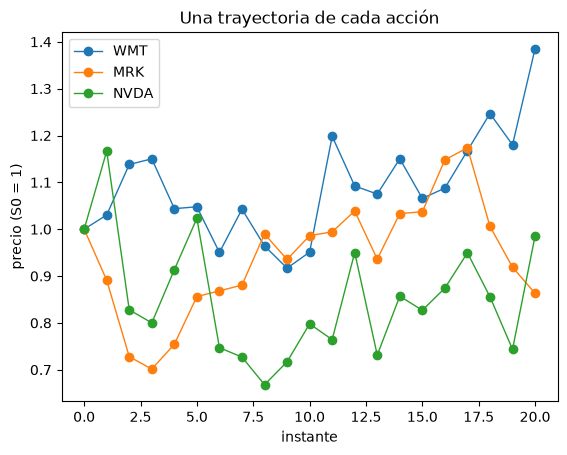

In [24]:
plt.plot(S[0], marker="o", lw=1)
plt.legend(acciones)
plt.xlabel("instante"); plt.ylabel("precio (S0 = 1)"); plt.title("Una trayectoria de cada acción")
plt.show()

## 6. Payoff de la cesta asiática

Para cada trayectoria:
1. Media geométrica **normalizada** de cada acción: $\left(\prod_{j=1}^{n} S_j / S_0\right)^{1/n}$
2. Se suman las 3 medias geométricas
3. Se resta el strike $E$ y se toma el máximo con 0

In [25]:
G = np.exp(np.log(precios / S0).mean(axis=1))    # media geométrica normalizada: (trayectorias, 3)
cesta = G.sum(axis=1)                            # suma de las 3 acciones
payoff = np.maximum(cesta - E, 0)                # V_T de cada trayectoria

## 7. Valor presente y prima

La prima es el valor medio del payoff traído a hoy con capitalización continua: $e^{-\mu T}\cdot \overline{V_T}$. El error estándar mide la imprecisión por usar un número finito de trayectorias.

In [26]:
prima = np.exp(-mu * T) * payoff.mean()
error = np.exp(-mu * T) * payoff.std(ddof=1) / np.sqrt(n_trayectorias)

print(f"Prima de la call asiática: {prima:.4f}  (± {error:.4f})")
print(f"Trayectorias con payoff > 0: {(payoff > 0).mean():.1%}")

Prima de la call asiática: 0.3061  (± 0.0020)
Trayectorias con payoff > 0: 38.7%


## 8. Valor en distintos instantes

La Descripción técnica pide $Y = V_T^h \cdot e^{-\mu (n_{pasos} - t_n)\Delta t}$, con $h$ la simulación y $t_n$ el instante de referencia. Con $t_n = 0$ es el valor de hoy y con $t_n = n_{pasos}$ no hay descuento.

- **A)** `Y`: un valor por simulación y por instante.
- **B)** `prima_t`: la media de `Y` sobre todas las simulaciones, una prima por instante.

In [28]:
t_n = np.arange(n_times + 1)                                  # 0, 1, ..., 20

Y = payoff[:, None] * np.exp(-mu * (n_times - t_n) * dt)      # A) (trayectorias, instantes)
prima_t = Y.mean(axis=0)                                      # B) una prima por instante

print("Forma de Y:", Y.shape)
print(f"Prima en t_n = 0: {prima_t[0]:.4f}   |   en t_n = {n_times}: {prima_t[-1]:.4f}")

Forma de Y: (100000, 21)
Prima en t_n = 0: 0.3061   |   en t_n = 20: 0.3218
